# Create Card Strength Metric

**Workflow:**
- Load and filter raw Scryfall data for Commander-legal cards.
- Fetch and join EDHREC inclusion data (play rate) to serve as training labels.
- Export the final dataset for model training.

In [1]:
import os
import pandas as pd
import numpy as np
import json
import matplotlib.pyplot as plt
import seaborn as sns

from common.dataset_filter import filter_dataset
from common.text_normalizing import sluggify_card_name

In [2]:
INPUT_DATA_PATH = "../data/scryfall/oracle-cards-20251022090300.json"
OUTPUT_DATA_PATH = "../data/training/card_strength_metric.xlsx"
EDHREC_CARD_DIRECTORY = "../data/edhrec/cards"

In [3]:
df = pd.read_json(INPUT_DATA_PATH)
df = filter_dataset(df)

print(f"shape: {df.shape}")
df.head()

shape: (29677, 15)


,oracle_id,name,card_faces,mana_cost,cmc,type_line,oracle_text,power,toughness,loyalty,colors,color_identity,keywords,game_changer,set
0,00037840-6089-42ec-8c5c-281f9f474504,"Nissa, Worldsoul Speaker",NaN,{3}{G},4.0,Legendary Creature — Elf Druid,"Landfall — Whenever a land you control enters,...",3,3,NaN,[G],[G],[Landfall],False,drc
1,0004ebd0-dfd6-4276-b4a6-de0003e94237,Static Orb,NaN,{3},3.0,Artifact,"As long as this artifact is untapped, players ...",NaN,NaN,NaN,[],[],[],False,7ed
2,0006faf6-7a61-426c-9034-579f2cfcfa83,Sensory Deprivation,NaN,{U},1.0,Enchantment — Aura,Enchant creature\nEnchanted creature gets -3/-0.,NaN,NaN,NaN,[U],[U],[Enchant],False,m14
3,0007c283-5b7a-4c00-9ca1-b455c8dff8c3,Road of Return,NaN,{G}{G},2.0,Sorcery,Choose one —\n• Return target permanent card f...,NaN,NaN,NaN,[G],[G],[Entwine],False,c19
4,000d5588-5a4c-434e-988d-396632ade42c,Storm Crow,NaN,{1}{U},2.0,Creature — Bird,Flying (This creature can't be blocked except ...,1,2,NaN,[U],[U],[Flying],False,9ed


## Join EDHREC Inclusion Data

- Iterate through cards and match them with scraped EDHREC json files.
- Calculate `inclusion_rate` and `log_inclusion_rate` (Popularity / Potential Decks).
- Drop basic lands and cards without available popularity data.

**TODO (for later):**
- For commanders: use higher play rate out of commander play rate or play rate in 99
- Weight the play rate per bracket (bracket 1 contributes 1, bracket 5 contributes 5)
- Track play rate (or frequency) per commander to determine if a card is niche or broad (boost good niche cards) 

In [6]:
play_rate_data = []
indices_to_drop = []

for idx, row in df.iterrows():
    name = row["name"]
    print(f"({idx+1}/{len(df)}) Processing {name}...")

    if name in ["Forest", "Mountain", "Swamp", "Island", "Plains"]:
        print(f"  -> Skip basic land, drop row\n")
        indices_to_drop.append(idx)
        continue

    slugs = sluggify_card_name(name)
    if isinstance(slugs, str):
        slugs = [slugs]

    inclusion = potential_decks = inclusion_rate = log_inclusion_rate = 0
    for slug in slugs:
        filename = f"{slug}.json"
        path = os.path.join(EDHREC_CARD_DIRECTORY, filename)
        if not os.path.exists(path):
            continue
        try:
            with open(path, 'r', encoding='utf-8') as f:
                json_dict = json.load(f)
            inclusion = json_dict["container"]["json_dict"]["card"]["inclusion"]
            potential_decks = json_dict["container"]["json_dict"]["card"]["potential_decks"]
            inclusion_rate = np.float64(inclusion) / np.float64(potential_decks)
            log_inclusion_rate = np.log10(inclusion_rate)
            break
        except (KeyError, json.JSONDecodeError):
            continue

    if inclusion == 0:
        print(f"  -> No data found, drop row\n")
        indices_to_drop.append(idx)
        continue

    play_rate_data.append({
        'index': idx,
        'inclusion': inclusion,
        'potential_decks': potential_decks,
        'inclusion_rate': inclusion_rate,
        'log_inclusion_rate': log_inclusion_rate
    })

df = df.drop(index=indices_to_drop)
results_df = pd.DataFrame(play_rate_data).set_index('index')
df = df.join(results_df)

print(f"\nProcessing complete.")
print(f"{len(indices_to_drop)} rows dropped")
print(f"DataFrame shape: {df.shape}")

(1/29677) Processing Nissa, Worldsoul Speaker...
(2/29677) Processing Static Orb...
(3/29677) Processing Sensory Deprivation...
(4/29677) Processing Road of Return...
(5/29677) Processing Storm Crow...
(6/29677) Processing Walking Sponge...
(7/29677) Processing Ravnica at War...
(8/29677) Processing Greta, Sweettooth Scourge...
(9/29677) Processing Torrent of Fire...
(10/29677) Processing Wyluli Wolf...
(11/29677) Processing Pteramander...
(12/29677) Processing Nantuko Elder...
(13/29677) Processing Vedalken Heretic...
(14/29677) Processing Waterknot...
(15/29677) Processing Ruthless Knave...
(16/29677) Processing Palinchron...
(17/29677) Processing Hua Tuo, Honored Physician...
(18/29677) Processing Veil of Summer...
(19/29677) Processing Disposal Mummy...
(20/29677) Processing Wei Strike Force...
(21/29677) Processing Marang River Prowler...
(22/29677) Processing Aura Graft...
(23/29677) Processing Murk Dwellers...
(24/29677) Processing Whispering Shade...
(25/29677) Processing Sahee

## Create Power Scores

- Scale log-inclusion rates to a standardized 25-99 range to create `log10_power_score`.
- Visualize the score distribution to ensure data quality.

Scores calculated! Range: 25.0000 to 99.0000


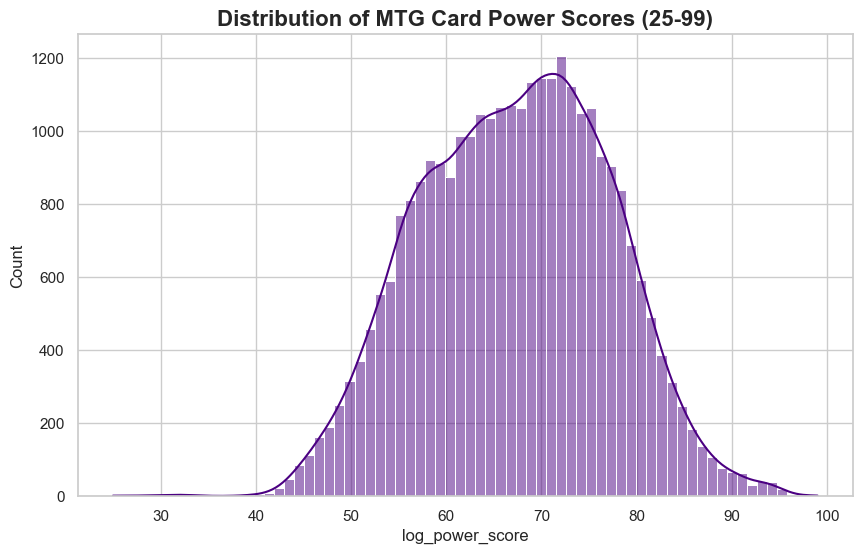

In [7]:
MIN_SCORE = 25
MAX_SCORE = 99
log_min = df['log_inclusion_rate'].min()
log_max = df['log_inclusion_rate'].max()
df['log_power_score'] = MIN_SCORE + ((df['log_inclusion_rate'] - log_min) * (MAX_SCORE - MIN_SCORE)) / (log_max - log_min)

print(f"Scores calculated! Range: {df['log_power_score'].min():.4f} to {df['log_power_score'].max():.4f}")
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))
sns.histplot(df['log_power_score'], bins=70, kde=True, color='indigo')
plt.title('Distribution of MTG Card Power Scores (25-99)', fontsize=16, fontweight='bold')
plt.show()

## Dataset Export

In [9]:
print(f"Exporting to {OUTPUT_DATA_PATH}")
df.to_excel(OUTPUT_DATA_PATH, index=False)
print("Done")

Exporting to ../data/training/card_strength_metric.xlsx
Done
